In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# AI4I 2020 Predictive Maintenance Dataset

## 1. Overview

This dataset simulates sensor and operating data from a **milling machine** in a manufacturing setting. It is used for **predictive maintenance**: predicting whether a machine will fail and *which type of failure* occurs, based on process conditions.

| Property | Value |
|---|---|
| Rows (observations) | 10,000 |
| Columns (features + targets) | 14 |
| Missing values | None |
| Duplicate rows | None |
| Data types | 2 categorical/ID columns, 5 numerical sensor columns, 7 integer columns (ID and binary labels) |
| Task | Binary classification (`Machine failure`) and multi-label classification (failure modes) |

**Class imbalance:** only **339 of 10,000** records (**3.39%**) are machine failures, so the target is strongly imbalanced. 

---

## 2. Column Descriptions

### Identifiers

| Column | Type | Description |
|---|---|---|
| `UDI` | int | Unique row identifier (1 to 10,000). It is only an index and should **not** be used as a feature. |
| `Product ID` | string | Unique product/serial code made of the quality letter (L/M/H) plus a serial number (e.g. `M14860`). All 10,000 values are unique, so it carries no predictive information beyond `Type`. |

### Input Features

| Column | Type | Unit | Range | Mean | Description |
|---|---|---|---|---|---|
| `Type` | categorical | n/a | L, M, H | n/a | Product quality variant: **L** = Low (60%, 6,000 rows), **M** = Medium (30%, 2,997 rows), **H** = High (10%, 1,003 rows). Needs encoding (one-hot or ordinal). |
| `Air temperature [K]` | float | Kelvin | 295.3 to 304.5 | 300.0 | Ambient air temperature around the machine. Simulated as a random walk, normalised to a standard deviation of 2 K around 300 K. |
| `Process temperature [K]` | float | Kelvin | 305.7 to 313.8 | 310.0 | Temperature of the machining process. Simulated as a random walk, normalised to a standard deviation of 1 K around 310 K, and sits about 10 K above air temperature. |
| `Rotational speed [rpm]` | int | rpm | 1,168 to 2,886 | 1,539 | Spindle rotational speed, derived from a power of 2,860 W with added noise. Has a few high-speed outliers. |
| `Torque [Nm]` | float | Newton-metres | 3.8 to 76.6 | 40.0 | Torque applied by the spindle, roughly normally distributed around 40 Nm (SD about 10 Nm). It is inversely related to rotational speed. |
| `Tool wear [min]` | int | minutes | 0 to 253 | 108.0 | Cumulative time the cutting tool has been in use. Quality variants add different wear per run: H adds 5 min, M adds 3 min, L adds 2 min. |

### Target Variables

| Column | Type | Positives | Description |
|---|---|---|---|
| `Machine failure` | binary (0/1) | 339 (3.39%) | **Main target.** 1 if the machine failed in this run for **any** of the failure modes below. |
| `TWF` | binary (0/1) | 46 (0.46%) | **Tool Wear Failure.** The tool is replaced or fails once its wear reaches a randomly chosen value between about 200 and 240 min. |
| `HDF` | binary (0/1) | 115 (1.15%) | **Heat Dissipation Failure.** Occurs when the air/process temperature difference is below 8.6 K **and** the rotational speed is below 1,380 rpm. |
| `PWF` | binary (0/1) | 95 (0.95%) | **Power Failure.** Occurs when power (torque × rotational speed in rad/s) falls below 3,500 W or exceeds 9,000 W. |
| `OSF` | binary (0/1) | 98 (0.98%) | **Overstrain Failure.** Occurs when tool wear × torque exceeds a limit that depends on `Type`: 11,000 minNm (L), 12,000 (M), 13,000 (H). |
| `RNF` | binary (0/1) | 19 (0.19%) | **Random Failure.** Each run has a 0.1% chance of failing regardless of process parameters. |

---

## 3. Notes on the Targets

- `Machine failure` is meant to be 1 whenever **at least one** of `TWF`, `HDF`, `PWF`, `OSF`, `RNF` is 1.
- The data has a few **inconsistencies** with that rule: 9 rows have `Machine failure = 1` but no failure mode flagged, and 18 rows have `RNF = 1` with `Machine failure = 0`. Decide how to handle these during cleaning.
- Most failures have a single cause (306 of 339), but some rows have 2 or 3 simultaneous failure modes.
- **Data leakage warning:** if you predict `Machine failure`, **drop** `TWF`, `HDF`, `PWF`, `OSF` and `RNF` from the features (and `UDI`, `Product ID`), because they directly define the target.
- Failure rate by product type: **L** 3.92%, **M** 2.77%, **H** 2.09%.

---

## 4. Suggested Workflow

1. Exploratory data analysis: distributions, correlations, outliers (especially `Rotational speed [rpm]`).
2. Feature engineering: temperature difference (`Process − Air`), power (`Torque × speed × 2π/60`), wear × torque.
3. Encode `Type`, drop identifier columns, and scale numerical features where needed.
4. Stratified train/test split to preserve the 3.39% failure ratio.
5. Train and compare models (e.g. Logistic Regression, Random Forest, XGBoost) with imbalance handling.
6. Evaluate with a confusion matrix, precision/recall/F1, and ROC/PR curves.

**Source:** AI4I 2020 Predictive Maintenance Dataset (UCI Machine Learning Repository), a synthetic dataset that reflects real predictive-maintenance data.

In [25]:
df = pd.read_csv('../dataset/AI4I_Dataset.csv')
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [8]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [11]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [10]:
print("The dataset contains {} rows and {} columns.".format(df.shape[0], df.shape[1]))
print("The dataset contains columns: {}".format(df.columns.tolist()))

The dataset contains 10000 rows and 14 columns.
The dataset contains columns: ['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [12]:
COLORS = {0: "#4C72B0", 1: "#C44E52"}   # blue = no failure, red = failure

# Helper: 3 plots for any numerical feature
def num_plot(col, unit, bins=40):
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

    # 1) Histogram + KDE: shape of the distribution
    sns.histplot(df[col], bins=bins, kde=True, ax=ax[0], color="#4C72B0")
    ax[0].axvline(df[col].mean(), color="red", ls="--", label=f"Mean = {df[col].mean():.1f}")
    ax[0].axvline(df[col].median(), color="green", ls="--", label=f"Median = {df[col].median():.1f}")
    ax[0].set(title=f"Distribution of {col}", xlabel=unit)
    ax[0].legend()

    # 2) Boxplot: spread and outliers
    sns.boxplot(x=df[col], ax=ax[1], color="#8DA0CB")
    ax[1].set(title=f"Boxplot of {col}", xlabel=unit)

    # 3) Violin by target: does the feature differ between healthy and failed?
    sns.violinplot(data=df, x="Machine failure", y=col, hue="Machine failure",
                   palette=COLORS, legend=False, inner="quartile", ax=ax[2])
    ax[2].set(title=f"{col} vs Machine failure",
              xlabel="Machine failure (0 = No, 1 = Yes)", ylabel=unit)

    plt.tight_layout()
    plt.show()
    print(f"Skewness: {df[col].skew():.2f}")
    print(df.groupby("Machine failure")[col].mean().round(1).rename({0: "Mean (no failure)", 1: "Mean (failure)"}))

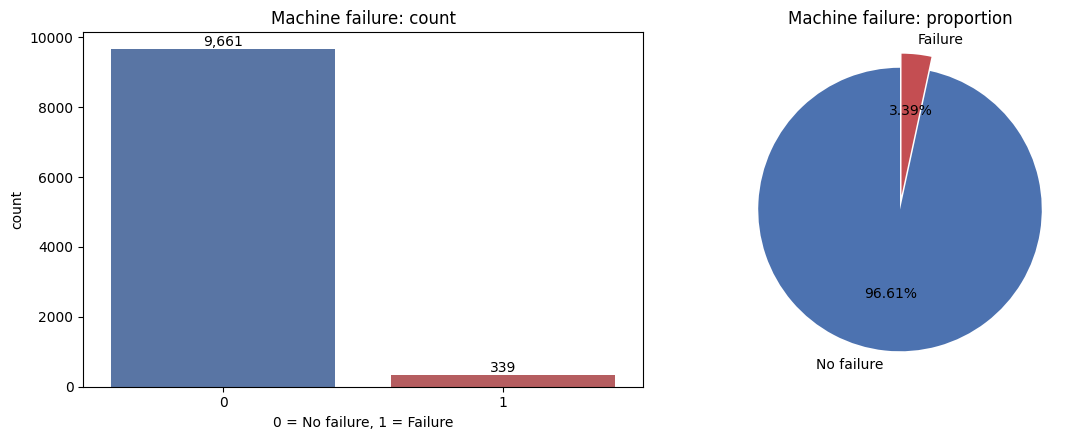

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
counts = df["Machine failure"].value_counts().sort_index()

sns.countplot(data=df, x="Machine failure", hue="Machine failure",
              palette=COLORS, legend=False, ax=ax[0])
for i, v in enumerate(counts):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[0].set(title="Machine failure: count", xlabel="0 = No failure, 1 = Failure")

ax[1].pie(counts, labels=["No failure", "Failure"], autopct="%1.2f%%",
          colors=[COLORS[0], COLORS[1]], explode=(0, 0.1), startangle=90)
ax[1].set_title("Machine failure: proportion")
plt.tight_layout()
plt.show()

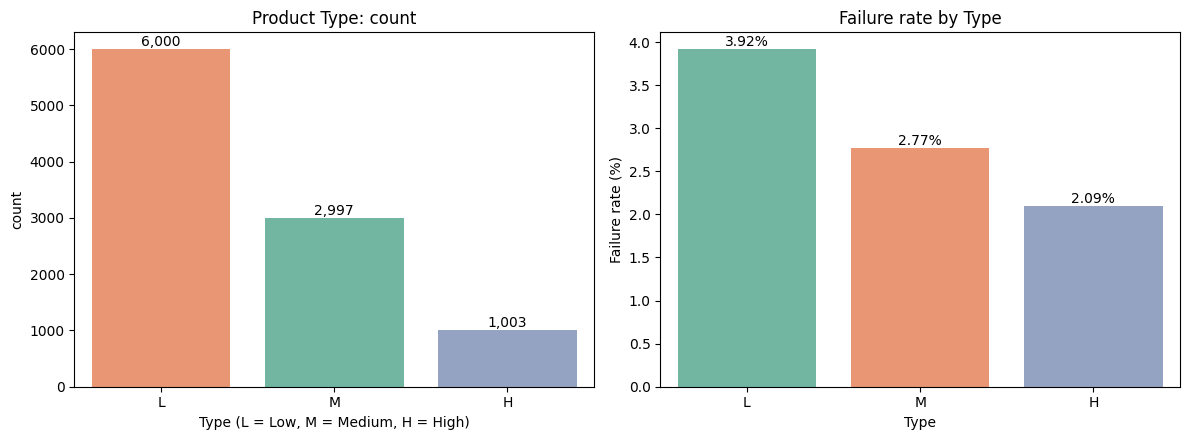

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
order = ["L", "M", "H"]

sns.countplot(data=df, x="Type", order=order, hue="Type", palette="Set2", legend=False, ax=ax[0])
for p in ax[0].patches:
    ax[0].text(p.get_x() + p.get_width()/2, p.get_height(), f"{int(p.get_height()):,}",
               ha="center", va="bottom")
ax[0].set(title="Product Type: count", xlabel="Type (L = Low, M = Medium, H = High)")

rate = df.groupby("Type")["Machine failure"].mean().reindex(order) * 100
sns.barplot(x=rate.index, y=rate.values, hue=rate.index, palette="Set2", legend=False, ax=ax[1])
for i, v in enumerate(rate.values):
    ax[1].text(i, v, f"{v:.2f}%", ha="center", va="bottom")
ax[1].set(title="Failure rate by Type", xlabel="Type", ylabel="Failure rate (%)")
plt.tight_layout()
plt.show()

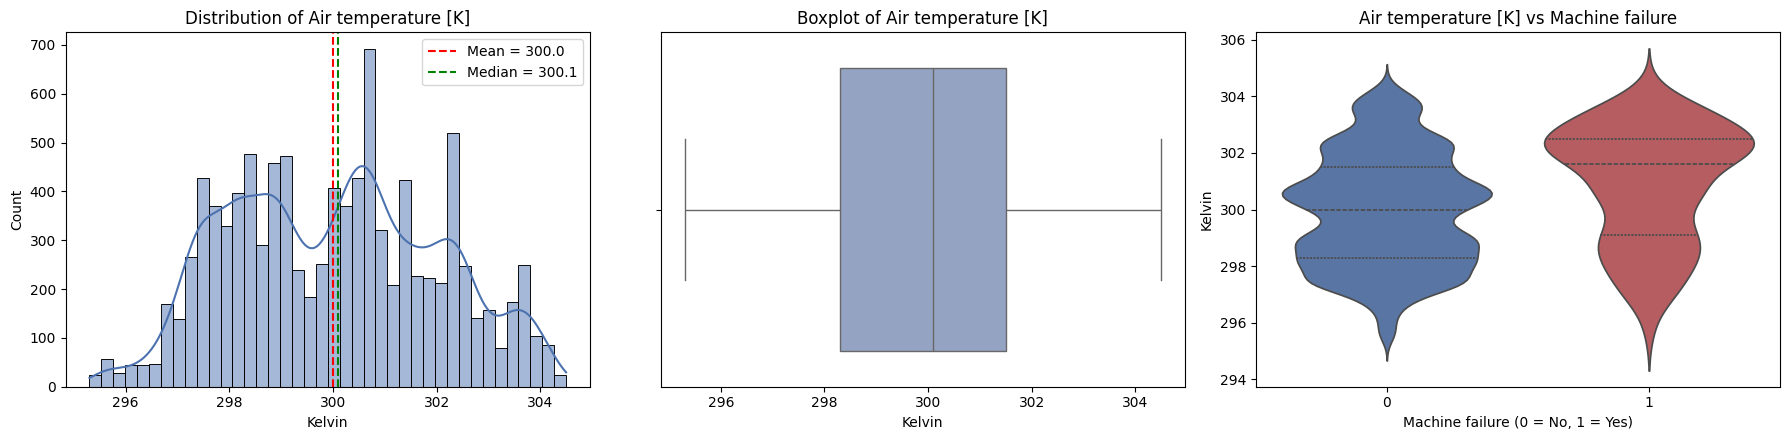

Skewness: 0.11
Machine failure
Mean (no failure)    300.0
Mean (failure)       300.9
Name: Air temperature [K], dtype: float64


In [15]:
num_plot("Air temperature [K]", "Kelvin")

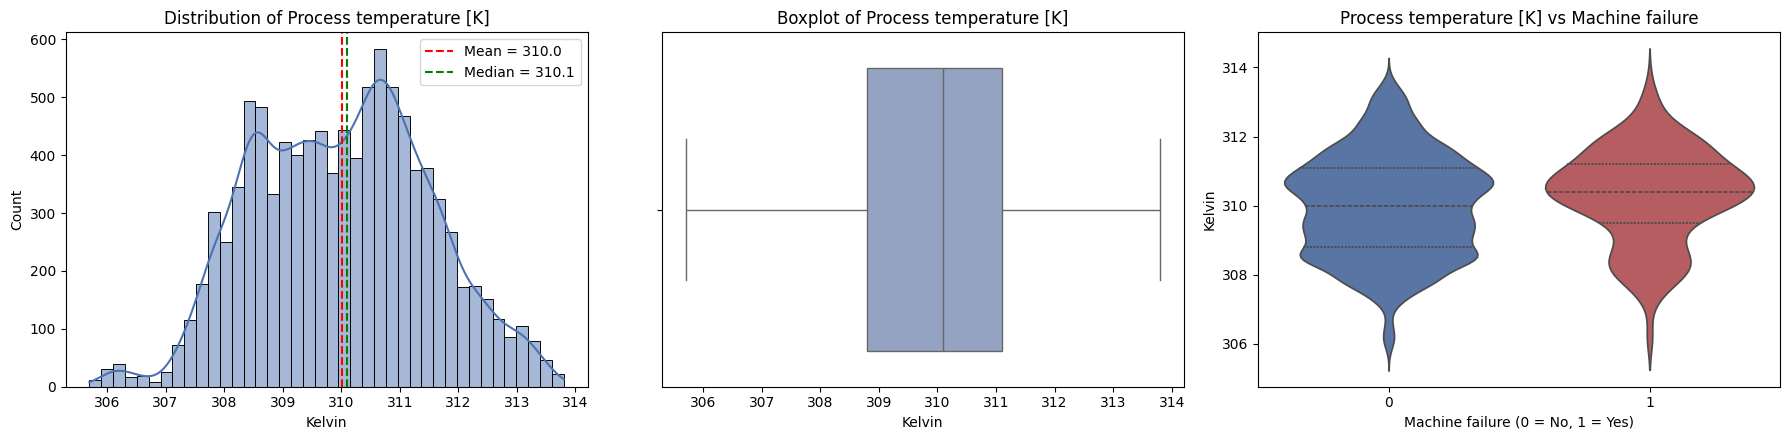

Skewness: 0.02
Machine failure
Mean (no failure)    310.0
Mean (failure)       310.3
Name: Process temperature [K], dtype: float64


In [16]:
num_plot("Process temperature [K]", "Kelvin")

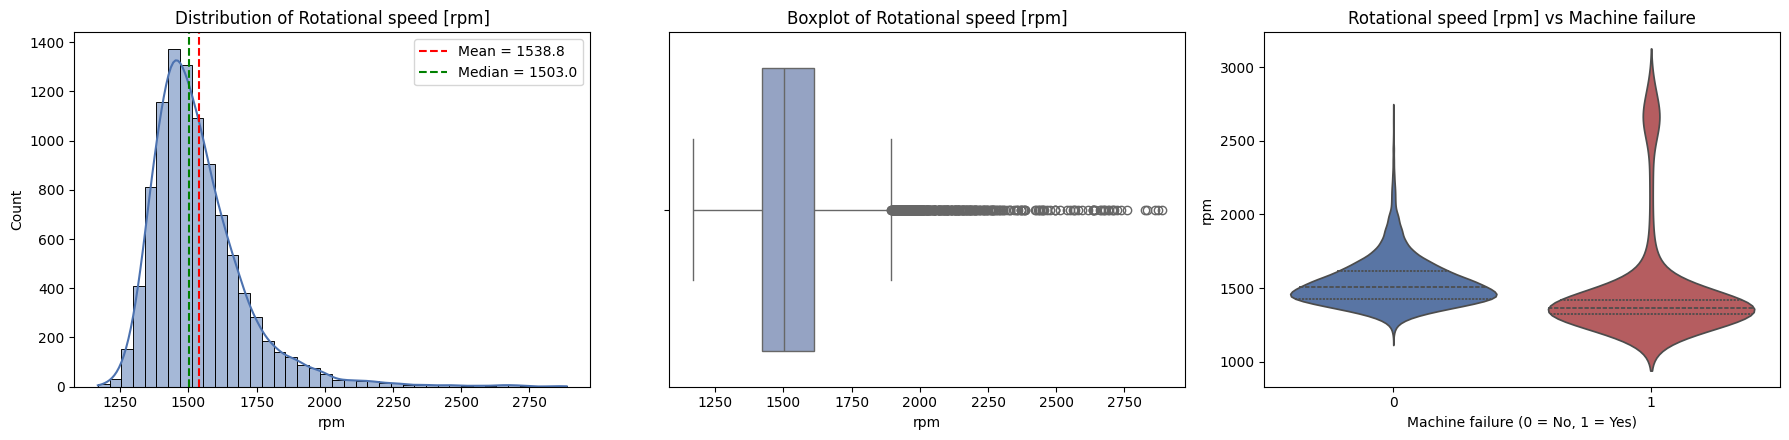

Skewness: 1.99
Machine failure
Mean (no failure)    1540.3
Mean (failure)       1496.5
Name: Rotational speed [rpm], dtype: float64


In [17]:
num_plot("Rotational speed [rpm]", "rpm")

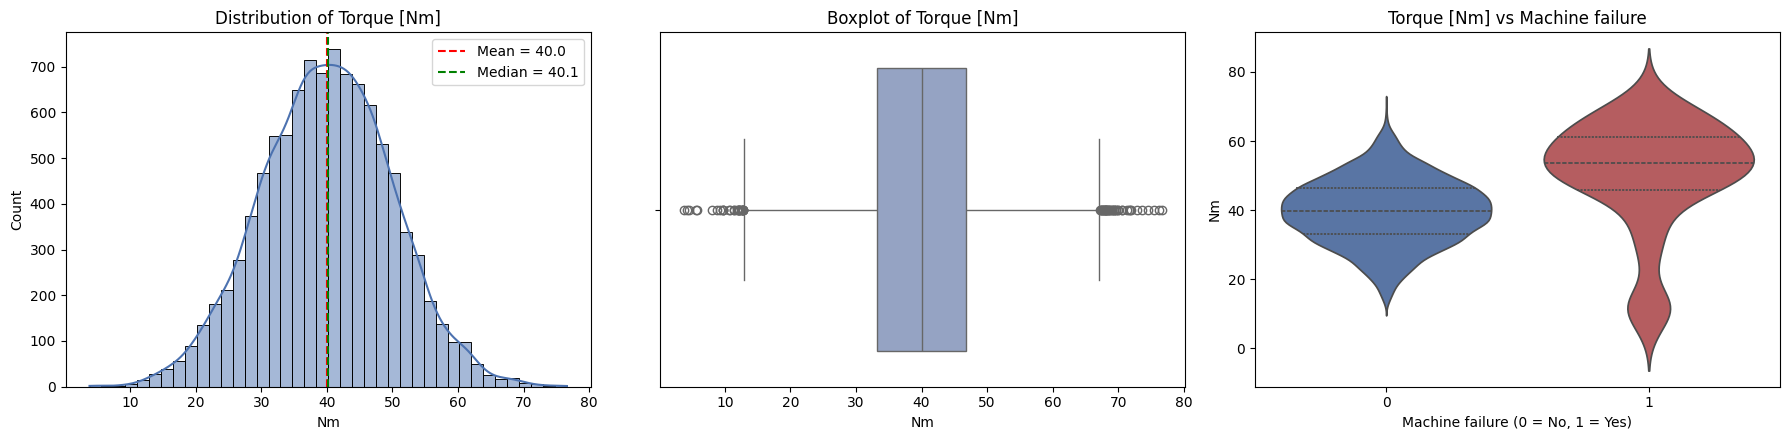

Skewness: -0.01
Machine failure
Mean (no failure)    39.6
Mean (failure)       50.2
Name: Torque [Nm], dtype: float64


In [18]:
num_plot("Torque [Nm]", "Nm")

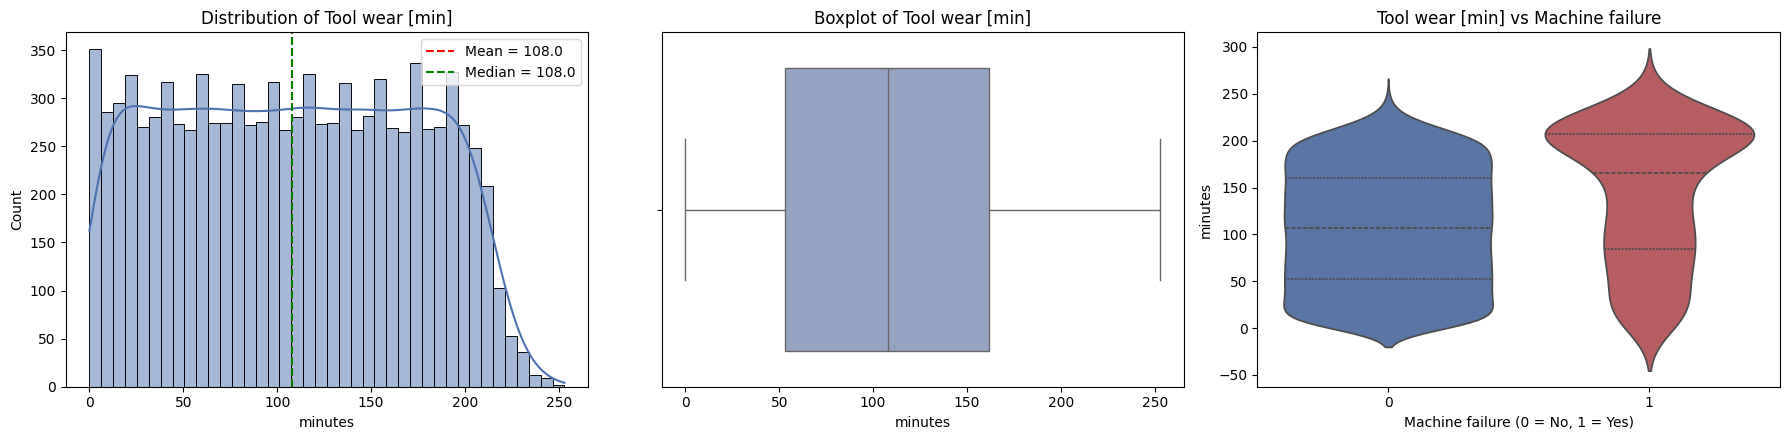

Skewness: 0.03
Machine failure
Mean (no failure)    106.7
Mean (failure)       143.8
Name: Tool wear [min], dtype: float64


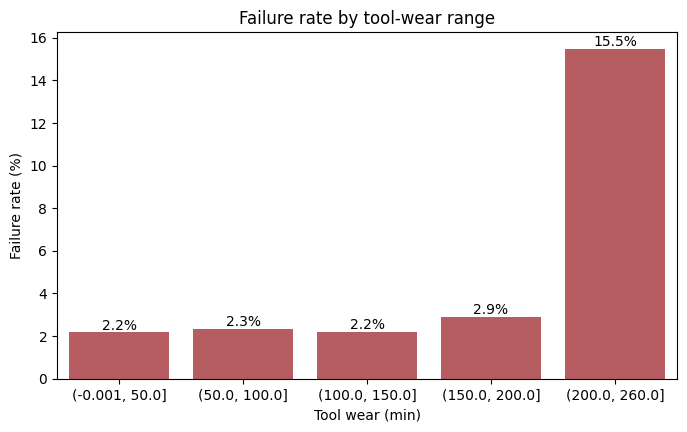

In [19]:
num_plot("Tool wear [min]", "minutes")

# Failure rate per tool-wear range
df["wear_bin"] = pd.cut(df["Tool wear [min]"], bins=[0, 50, 100, 150, 200, 260], include_lowest=True)
wear_rate = df.groupby("wear_bin", observed=True)["Machine failure"].mean() * 100

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(x=wear_rate.index.astype(str), y=wear_rate.values, color="#C44E52")
for i, v in enumerate(wear_rate.values):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom")
plt.title("Failure rate by tool-wear range")
plt.xlabel("Tool wear (min)")
plt.ylabel("Failure rate (%)")
plt.show()
df.drop(columns="wear_bin", inplace=True)

In [21]:
corr_columns = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
                "Torque [Nm]", "Tool wear [min]", "Machine failure"]
corr_matrix = df[corr_columns].corr()
corr_matrix.style

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Air temperature [K],1.000000,0.876107,0.022670,-0.013778,0.013853,0.082556
Process temperature [K],0.876107,1.000000,0.019277,-0.014061,0.013488,0.035946
Rotational speed [rpm],0.022670,0.019277,1.000000,-0.875027,0.000223,-0.044188
Torque [Nm],-0.013778,-0.014061,-0.875027,1.000000,-0.003093,0.191321
Tool wear [min],0.013853,0.013488,0.000223,-0.003093,1.000000,0.105448
Machine failure,0.082556,0.035946,-0.044188,0.191321,0.105448,1.000000


# Data Preprocessing

In [22]:
df_copy = df.copy()

In [28]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(
    categories=[
        ["L", "M", "H"]
    ]
)

df_copy[["Type_encoded"]] = encoder.fit_transform(
    df_copy[["Type"]]
)
df_copy.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Type_encoded
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,1.0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,0.0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,0.0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,0.0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,0.0


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
